# State metrics on an HSMPO: comparison with Qibo

`mpstab.models.metrics` evaluates state metrics directly on the state an `HSMPO` represents. This tutorial checks them against Qibo's statevector versions in two separate sections:

1. the **Meyer-Wallach entanglement**, and its convergence to the statevector value as the bond dimension grows;
2. the **stabilizer Rényi entropy**, which tells stabilizer states apart from states carrying magic.

## 1. Meyer-Wallach entanglement

The Meyer-Wallach global entanglement of an $n$-qubit pure state is the average single-qubit linear entropy,

$$
Q(\psi) = 2 \left(1 - \frac{1}{n} \sum_{k=0}^{n-1} \mathrm{Tr}\,\rho_k^2\right),
$$

with $\rho_k$ the reduced state of qubit $k$. It is 0 for product states and 1 when every qubit is maximally entangled with the rest.

For a statevector, Qibo already provides it as `qibo.quantum_info.meyer_wallach_entanglement`, and we use that as the exact reference. `mpstab` adds `meyer_wallach_mps`, which evaluates $Q$ on the state an `HSMPO` represents, $C|\psi_{\mathrm{MPS}}\rangle$. The single-qubit reduced states cannot be read off the MPS sites, because the Clifford part $C$ mixes them. Each purity is rebuilt from the qubit's Bloch vector instead,

$$
\mathrm{Tr}\,\rho_k^2 = \frac{1}{2}\left(1 + \langle X_k\rangle^2 + \langle Y_k\rangle^2 + \langle Z_k\rangle^2\right)
\quad\Longrightarrow\quad
Q = 1 - \frac{1}{n} \sum_{k}\sum_{P \in \{X,Y,Z\}} \langle P_k\rangle^2 .
$$

Every $\langle P_k\rangle$ is backpropagated through $C$ and contracted against the MPS, so the estimate costs $3n$ contractions and is exact up to the MPS truncation. In this tutorial we cap the bond dimension $\chi$ and watch the HSMPO estimate converge to the statevector value as $\chi$ grows.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from qibo import Circuit, gates, set_backend
from qibo.quantum_info import meyer_wallach_entanglement, stabilizer_renyi_entropy

from mpstab import HSMPO
from mpstab.models.metrics import meyer_wallach_mps, stabilizer_renyi_entropy_mps

set_backend("numpy")

[Qibo 0.3.6|INFO|2026-10-28 15:15:59]: Using numpy backend on /CPU:0


### A circuit that builds up entanglement

We use a kicked Ising circuit: each step applies non-Clifford single-qubit kicks $R_X(\theta_h) R_Z(\theta_z)$ on every qubit, then $R_{ZZ}(-\pi/2)$ couplings on the even and odd bonds, written as `CNOT · RZ(-π/2) · CNOT`. The couplings are Clifford and go to the stabilizer part. The kicks are the magic gates, and the MPS absorbs them as dressed Pauli rotations, so its bond dimension grows with the number of steps.

In [4]:
def kicked_ising(nqubits, steps, theta_h, theta_z):
    circuit = Circuit(nqubits)
    for _ in range(steps):
        for q in range(nqubits):
            circuit.add(gates.RX(q, theta_h))
            circuit.add(gates.RZ(q, theta_z))
        for start in (0, 1):
            for q in range(start, nqubits - 1, 2):
                circuit.add(gates.CNOT(q, q + 1))
                circuit.add(gates.RZ(q + 1, -np.pi / 2))
                circuit.add(gates.CNOT(q, q + 1))
    return circuit


nqubits, steps = 12, 6
circuit = kicked_ising(nqubits, steps, theta_h=0.8, theta_z=0.3)
print(f"{nqubits} qubits, {steps} steps, {len(circuit.queue)} gates")

12 qubits, 6 steps, 342 gates


### Statevector reference

Twelve qubits fit comfortably in a statevector, so Qibo gives us the exact $Q$.

In [6]:
exact = float(meyer_wallach_entanglement(circuit.copy()().state()))
print(f"Statevector Q = {exact:.10f}")

Statevector Q = 0.7356698332


### HSMPO estimate for increasing bond dimension

For each $\chi$ we build an `HSMPO` with `max_bond_dimension=chi` and evaluate `meyer_wallach_mps`. The quimb engine divides each expectation value by the norm of the truncated MPS, so the $\langle P_k\rangle$ entering $Q$ are always those of a normalised state.

In [7]:
bond_dimensions = [1, 2, 4, 8, 16, 32]
estimates = []

print(f"{'chi':>4} {'Q_chi':>12} {'|Q_chi - Q|':>12}")
for chi in bond_dimensions:
    hsmpo = HSMPO(ansatz=circuit.copy(), max_bond_dimension=chi)
    estimates.append(meyer_wallach_mps(hsmpo))
    print(f"{chi:>4} {estimates[-1]:>12.8f} {abs(estimates[-1] - exact):>12.2e}")

 chi        Q_chi  |Q_chi - Q|
   1   0.00000000     7.36e-01
   2   0.43393967     3.02e-01
   4   0.68614806     4.95e-02
   8   0.73028890     5.38e-03
  16   0.73564399     2.58e-05
  32   0.73566980     3.00e-08


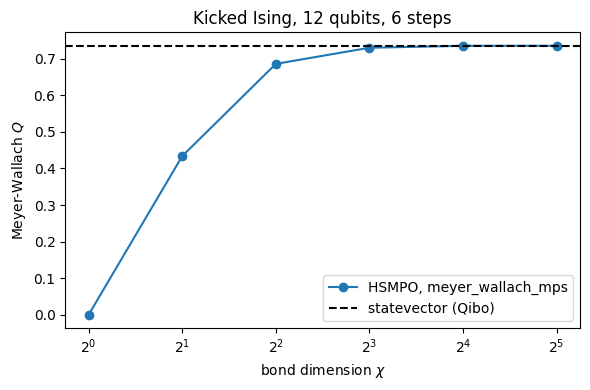

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(bond_dimensions, estimates, "o-", label="HSMPO, meyer_wallach_mps")
ax.axhline(exact, color="k", ls="--", label="statevector (Qibo)")
ax.set_xscale("log", base=2)
ax.set_xlabel(r"bond dimension $\chi$")
ax.set_ylabel(r"Meyer-Wallach $Q$")
ax.set_title(f"Kicked Ising, {nqubits} qubits, {steps} steps")
ax.legend()
fig.tight_layout()
plt.show()

### Reading the results

- At $\chi = 1$ the MPS is a product state. In this circuit the leftover Clifford part is local as well, because the $R_{ZZ}(-\pi/2)$ couplings commute and six of them compose to $Z \otimes Z$ up to a phase. The HSMPO therefore sees no entanglement at all and returns $Q = 0$.
- Here $Q_\chi$ approaches the exact value from below. Truncation discards the smallest Schmidt values, and with them part of the entanglement.
- The error falls quickly with $\chi$, from $0.74$ at $\chi = 1$ to about $3 \cdot 10^{-8}$ at $\chi = 32$, where the capped MPS is effectively exact for this state.

The same `meyer_wallach_mps` call works on circuits far beyond the reach of a statevector, since it only needs $3n$ contractions on the MPS.

## 2. Stabilizer Rényi entropy

The stabilizer Rényi entropy of order $\alpha$ measures how far a state is from the set of stabilizer states,

$$
M_\alpha(\psi) = \frac{1}{1 - \alpha} \log_2 \sum_{P} \frac{\langle\psi|P|\psi\rangle^{2\alpha}}{2^n},
$$

with the sum over all $4^n$ Pauli strings. It is zero if and only if $\psi$ is a stabilizer state. Qibo computes it exactly from a statevector with `qibo.quantum_info.stabilizer_renyi_entropy`. `stabilizer_renyi_entropy_mps` estimates it on an HSMPO by sampling Pauli strings uniformly and evaluating each $\langle P\rangle$ through the Clifford part and the MPS. Both return the total $M_\alpha$ in bits.

We compare two versions of the same kicked Ising circuit:

- **stabilizer:** with $\theta_h = \pi/2$ and $\theta_z = 0$ every gate is Clifford, so $M_2 = 0$;
- **magic:** with the kicks of section 1, $\theta_h = 0.8$ and $\theta_z = 0.3$, the state carries magic.

Uniform sampling is noisy. For a stabilizer state only $2^n$ of the $4^n$ Pauli strings have a nonzero expectation value, so the number of samples needed grows quickly with $n$. We therefore use 6 qubits and 3 steps, and repeat the estimate over several seeds to show its spread.

In [10]:
sre_qubits, sre_steps, n_samples = 6, 3, 2000
seeds = range(5)
sre_circuits = {
    "stabilizer": kicked_ising(sre_qubits, sre_steps, theta_h=np.pi / 2, theta_z=0.0),
    "magic": kicked_ising(sre_qubits, sre_steps, theta_h=0.8, theta_z=0.3),
}

sre_results = {}
print(f"{'circuit':>10} {'M2 exact':>9} {'M2 HSMPO (mean ± std)':>22}")
for name, sre_circuit in sre_circuits.items():
    exact_m2 = float(stabilizer_renyi_entropy(sre_circuit.copy()().state(), alpha=2))
    hsmpo = HSMPO(ansatz=sre_circuit.copy())
    samples = [
        stabilizer_renyi_entropy_mps(hsmpo, alpha=2, n_samples=n_samples, seed=seed)
        for seed in seeds
    ]
    sre_results[name] = (exact_m2, np.mean(samples), np.std(samples))
    print(f"{name:>10} {exact_m2:>9.4f} {np.mean(samples):>13.3f} ± {np.std(samples):.3f}")

   circuit  M2 exact  M2 HSMPO (mean ± std)
stabilizer    0.0000        -0.022 ± 0.096
     magic    3.0440         3.246 ± 0.173


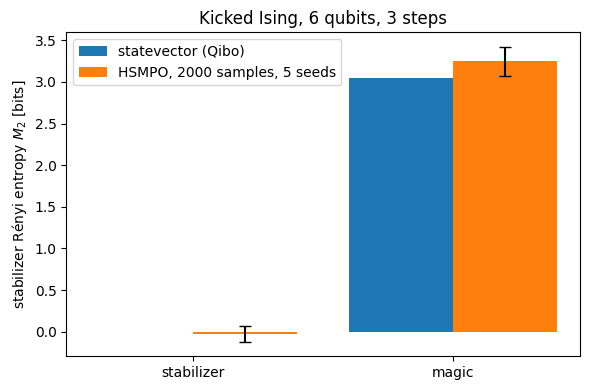

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
positions = np.arange(len(sre_results))
exact_values = [result[0] for result in sre_results.values()]
means = [result[1] for result in sre_results.values()]
stds = [result[2] for result in sre_results.values()]

ax.bar(positions - 0.2, exact_values, width=0.4, label="statevector (Qibo)")
ax.bar(
    positions + 0.2,
    means,
    width=0.4,
    yerr=stds,
    capsize=4,
    label=f"HSMPO, {n_samples} samples, {len(seeds)} seeds",
)
ax.set_xticks(positions, list(sre_results))
ax.set_ylabel(r"stabilizer Rényi entropy $M_2$ [bits]")
ax.set_title(f"Kicked Ising, {sre_qubits} qubits, {sre_steps} steps")
ax.legend()
fig.tight_layout()
plt.show()

### Reading the results

- On the stabilizer circuit Qibo gives exactly 0, and the HSMPO estimates scatter around 0 within their sampling error. Single estimates can come out negative, since the logarithm of a noisy sum is not bounded by the exact value.
- On the magic circuit both agree on a clearly nonzero $M_2$, so 2000 samples are enough to tell the two states apart. The mean estimate sits slightly above the exact value. The Pauli sum is estimated without bias, but its logarithm is biased low on average (Jensen's inequality), and dividing by $1 - \alpha = -1$ turns that into a bias upwards in $M_2$. The bias shrinks as the number of samples grows.
- Doubling the samples from 1000 to 2000 shrinks the spread over seeds by about $\sqrt{2}$, as expected for Monte Carlo. The spread is still the main limitation, and it grows with the number of qubits, because uniform sampling mostly picks Pauli strings with a vanishing expectation value. Sampling them with probability $\langle P\rangle^2 / 2^n$ instead (perfect Pauli sampling) would remove most of that variance.